# Three curve forms around one mean size: Rosin-Rammler, Swebrec and the crush-zone composition, and the cap at the in situ block

**Level 2: The method in practice** · Needs: 03-size-distribution/01-from-a-mean-size-to-a-curve · Reading time: about 25 minutes

## Objectives

The Rosin-Rammler curve has two known weaknesses: it underestimates fines and it has no upper limit on the fragment size. The engine ships two more curve forms around the same mean size, and a structural cap. This notebook compares them on one blast and says exactly what each one adds.

By the end you will have:

- built the Swebrec and the crush-zone curves for the Enusa blast `En1` and compared their P20, P50 and P80 with Rosin-Rammler's;
- verified all three against the curves the bake committed;
- varied the Swebrec undulation parameter, and applied the cap at the in situ block size to see what it changes.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The corpus and the reconstructed patterns | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The Swebrec function | Ouchterlony 2005, https://doi.org/10.1179/037178405x44539, as printed in Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 10 and 11) | the equation is reproduced with citation | `bf.swebrec` |
| The counter-example for Swebrec | Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 | cited only | none (a statement in the engine's own docstring) |
| The committed distributions of the Enusa case | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json`, field `distributions` |

## Method

**Swebrec** (Ouchterlony 2005, as printed in Amoako et al. 2022, Eqs. 10 and 11):

```
P(x) = 1 / (1 + f(x)),   f(x) = [ ln(x_max / x) / ln(x_max / x50) ]^b
```

Three parameters instead of two. The upper limit `x_max` fixes the coarse tail (the engine takes the larger of burden and spacing) and the undulation `b` shapes the fines. Amoako et al. state that the function "is able to predict fines better". The engine keeps a counter-example next to it: Babaeian et al. 2019 found Rosin-Rammler closer to image analysis at a bauxite mine, so Swebrec is not presented as strictly better.

**Crush-zone composition.** Two failure modes act at once: tensile fracture gives the coarse fragments and compressive-shear fracture around the hole gives the fines. The engine blends a coarse Rosin-Rammler branch with a second, finer branch by mass. The structure is sourced from Amoako et al. 2022, but the branch constants (crossover size, fines uniformity, fines fraction) are **not published** in any source held for this work, so they are plausible starting values and every result says so.

**Cap at the in situ block.** A blast breaks blocks and does not fuse them, so mass a curve places above the in situ block size `XB` is read as unbroken blocks at `XB`: `P_cap(x) = P(x)` below `XB` and 1 from `XB` up. This is a declared modelling choice of the engine, not a published relation.

### Step 1: three curves, one blast

The three arms `KuzRam`, `Swebrec` and `CrushZone` share the classical mean size and differ only in the curve, so each is asked for its `distribution` of the same blast `En1`. The cell prints the percentiles, the engine's note on the crush-zone constants, and draws the three curves.

curve          P20 (m)   P50 (m)   P80 (m)
kuz-ram         0.0732    0.4399    1.6679
swebrec         0.0347    0.4398    1.5666
crush-zone      0.0507    0.3895    1.5845
crush-zone constants are published: False
crush-zone parameters: CrushZoneParameters(crossover_m=0.01, fines_uniformity=0.8, fines_fraction=0.05, source='structure from Amoako, Jha and Zhong 2022 section 3 describing Kanchibotla et al. 1999 and Djordjevic 1999; the branch constants are NOT published in any source held for this work and are supplied by the caller')


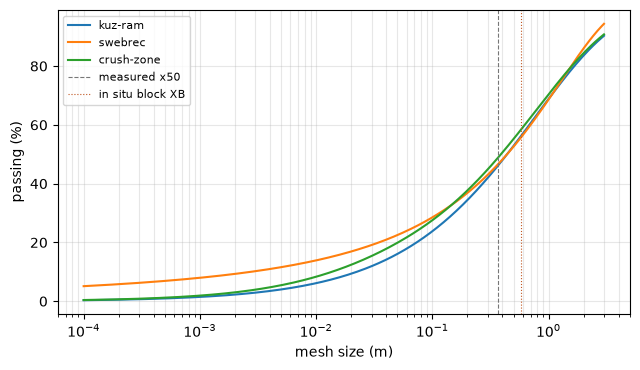

In [2]:
# Imports, then the three distributions of the same blast and their percentiles
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
arms = {"kuz-ram": bf.KuzRam(), "swebrec": bf.Swebrec(), "crush-zone": bf.CrushZone()}
curves = {name: arm.distribution(blast) for name, arm in arms.items()}
print(f"{'curve':<12}{'P20 (m)':>10}{'P50 (m)':>10}{'P80 (m)':>10}")
for name, curve in curves.items():
    print(f"{name:<12}{curve.percentile_m(0.2):>10.4f}{curve.percentile_m(0.5):>10.4f}{curve.percentile_m(0.8):>10.4f}")
print("crush-zone constants are published:", curves["crush-zone"].detail["constants_are_published"])
print("crush-zone parameters:", curves["crush-zone"].detail["parameters"])

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, curve in curves.items():
    ax.plot(curve.sizes_m, [100 * p for p in curve.passing], label=name)
ax.axvline(blast.x50_m, color="#777", lw=0.8, ls="--", label="measured x50")
ax.axvline(blast.XB_m, color="#c05621", lw=0.8, ls=":", label="in situ block XB")
ax.set_xscale("log")
ax.set_xlabel("mesh size (m)")
ax.set_ylabel("passing (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

### Step 2: check all three against the committed curves

The bake wrote the three curves of the representative blast of the Enusa case into `case.json`. The cell compares each point of each curve and prints the largest difference.

In [3]:
# Largest difference between each rebuilt curve and the committed one
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
print("committed representative blast:", artifact["representative_blast_id"])
for name, curve in curves.items():
    committed = artifact["distributions"][name]
    gap = max(abs(a - b) for a, b in zip(curve.passing, committed["passing"]))
    print(f"{name:<12} largest difference = {gap:.1e}   committed constants_published = {committed['constants_published']}")

committed representative blast: En1
kuz-ram      largest difference = 5.0e-07   committed constants_published = True
swebrec      largest difference = 5.0e-07   committed constants_published = True
crush-zone   largest difference = 5.0e-07   committed constants_published = False


### Step 3: the undulation parameter

The Swebrec undulation `b` has no published fit on this corpus, so the engine's default is a starting value. The cell scales it by 0.5, 1 and 1.5 and reports the effect on the fines (P20) and the coarse end (P80), with the mean size unchanged.

In [4]:
# Scale the default undulation and read the fines and the coarse end
default = bf.Swebrec().undulation
print(f"{'undulation b':>16}{'P20 (m)':>10}{'P50 (m)':>10}{'P80 (m)':>10}")
for factor in (0.5, 1.0, 1.5):
    curve = bf.Swebrec(undulation=default * factor).distribution(blast)
    print(f"{default * factor:>16.2f}{curve.percentile_m(0.2):>10.4f}{curve.percentile_m(0.5):>10.4f}{curve.percentile_m(0.8):>10.4f}")

    undulation b   P20 (m)   P50 (m)   P80 (m)
            1.00    0.0002    0.4398    2.9561
            2.00    0.0347    0.4398    1.5666
            3.00    0.0989    0.4398    1.1262


### Step 4: the cap at the in situ block

For `En1` the Rosin-Rammler P80 is larger than the in situ block `XB`. `cap_at_in_situ_block` clamps the curve to 1 from `XB` up, which lowers the upper percentiles but leaves the mean size alone unless it exceeds the block. The cell applies it to the three curves, then to the corpus blast `Rc1`, whose classical mean size exceeds its block.

In [5]:
# Cap each curve at the in situ block size and compare the upper percentiles and the oversize
print("in situ block of", blast.blast_id, "=", blast.XB_m, "m")
print(f"{'curve':<12}{'P80':>9}{'P80 capped':>14}{'mass above XB, uncapped':>34}")
for name, curve in curves.items():
    capped = bf.cap_at_in_situ_block(curve, blast.XB_m)
    print(f"{name:<12}{curve.percentile_m(0.8):>9.3f}{capped.percentile_m(0.8):>14.3f}{1 - curve.passing_at(blast.XB_m):>34.1%}")

rc1 = next(b for b in train if b.blast_id == "Rc1")
capped_rc1 = bf.cap_at_in_situ_block(arms["kuz-ram"].distribution(rc1), rc1.XB_m)
print(f"{rc1.blast_id}: classical mean size {capped_rc1.detail['uncapped_x50_m']:.3f} m, block {rc1.XB_m} m, capped mean {capped_rc1.x50_m:.3f} m, cap binds: {capped_rc1.detail['cap_binds']}")

in situ block of En1 = 0.58 m
curve             P80    P80 capped           mass above XB, uncapped
kuz-ram         1.668         0.575                             43.8%
swebrec         1.567         0.575                             44.3%
crush-zone      1.585         0.575                             41.6%
Rc1: classical mean size 0.720 m, block 0.68 m, capped mean 0.680 m, cap binds: True


## Results

**The three curves share a mean size and differ in the tails.** Swebrec puts more mass in the fines than Rosin-Rammler (a lower P20) and, with its upper limit, a finer upper end (a lower P80). The crush-zone blend moves the median itself: it adds a stated fraction of fines, so its P50 is below the classical mean size. All three match the committed curves to the file's rounding.

**The undulation moves both ends.** Scaling `b` by 0.5 and 1.5 changes the P20 by orders of magnitude and the P80 from about three metres to about one, with the mean size unchanged, which is why the engine treats it as an input to be set, not as something to fit silently.

**The cap changes the upper end and nothing else.** For `En1` each uncapped curve places roughly forty percent of its mass above the in situ block, which is physically impossible; the cap pulls the upper percentiles down to the block. For `Rc1` the classical mean size itself exceeds the block, and the cap binds on the mean.

**What this does not show.** None of these curves was compared with a measured size distribution, and the crush-zone constants are not published values. The differences in the table are differences between model forms, not differences in accuracy. That is why this topic has no state-of-the-art notebook: with only the mean size measured, there is nothing to rank the forms against.

## Summary

- Three curve forms share one mean size; they differ in the fines (Swebrec, crush zone) and the coarse end (Swebrec's upper limit).
- The crush-zone constants are not published values, and no measured size distribution exists to rank the forms.
- The cap at the in situ block removes oversize that is physically impossible and, where the mean exceeds the block, lowers the mean.
- Next: topic 04 turns from what a model predicts to how a prediction is judged.

## References

- Ouchterlony 2005, https://doi.org/10.1179/037178405x44539 (the Swebrec function)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 5, 10 and 11 and the description of the crush-zone mechanism)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (the bauxite counter-example for Swebrec)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/